In [2]:
%%html
<h1> E- Commerce Customer & Revenue Analysis (Intermediate level)</h1>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
os.makedirs('charts', exist_ok=True)

In [5]:
df = pd.read_csv('raw_ecommerce_orders_Analysis.csv')
raw_rows = len(df)
df.head()

,Order_ID,Order_Date,Customer_ID,Age_Group,Gender,Acquisition_Channel,Region,City,Category,Product,Quantity,Unit_Price,Unit_Cost,Discount_Pct,Shipping_Cost,Payment_Mode,Order_Status,Delivery_Days,Rating
0,ORD6659,24-07-2025,C0619,25-34,Female,Organic Search,West,Pune,Sports & Fitness,Fitness Tracker,1,2299,1300,0.00,0,Debit Card,Delivered,3.00,3.00
1,ORD5227,14-Jul-25,C0099,45-54,Female,Organic Search,South,Hyderabad,Electronics,Wireless Earbuds,2,1999,1100,0.00,0,UPI,Delivered,5.00,3.00
2,ORD7362,11-02-2025,C0869,55+,Female,Organic Search,West,Surat,Books & Stationery,Novel Bundle,1,799,380,0.00,49,Cash on Delivery,Delivered,3.00,5.00
3,ORD5254,28-Feb-25,C0110,45-54,Female,Social Media,North,Agra,Electronics,Phone Case,1,399,120,0.00,79,Debit Card,Delivered,2.00,NaN
4,ORD6968,10-04-2025,C0730,35-44,Female,Paid Ads,North,Lucknow,Sports & Fitness,Cricket Bat,4,1999,1000,20.00,0,UPI,Delivered,3.00,NaN


In [6]:
print('Shape:', df.shape)
df.info()

Shape: (2454, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2454 entries, 0 to 2453
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             2454 non-null   object 
 1   Order_Date           2454 non-null   object 
 2   Customer_ID          2454 non-null   object 
 3   Age_Group            2384 non-null   object 
 4   Gender               2454 non-null   object 
 5   Acquisition_Channel  2454 non-null   object 
 6   Region               2439 non-null   object 
 7   City                 2454 non-null   object 
 8   Category             2454 non-null   object 
 9   Product              2454 non-null   object 
 10  Quantity             2454 non-null   int64  
 11  Unit_Price           2454 non-null   int64  
 12  Unit_Cost            2454 non-null   int64  
 13  Discount_Pct         2434 non-null   float64
 14  Shipping_Cost        2454 non-null   int64  
 15  Payment_Mode        

In [7]:
print('Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nDuplicate rows:', df.duplicated().sum())
print('\nCategory values :', df['Category'].unique())
print('\nRegion values   :', df['Region'].unique())
print('\nStatus values   :', df['Order_Status'].unique())
print('\nChannel values  :', df['Acquisition_Channel'].unique())
print('\nInvalid quantity (<=0):', (df['Quantity'] <= 0).sum())
print('Invalid ratings (not 1-5):', (~df['Rating'].dropna().between(1, 5)).sum())
print('Date samples:', df['Order_Date'].sample(5, random_state=1).tolist())
print('\nUnit_Price vs product median (possible typos):')
med = df.groupby('Product')['Unit_Price'].transform('median')
print((df['Unit_Price'] > 3 * med).sum(), 'rows have price > 3x product median')

Missing values:
Age_Group         70
Region            15
Discount_Pct      20
Payment_Mode      25
Delivery_Days     93
Rating           760
dtype: int64

Duplicate rows: 30

Category values : ['Sports & Fitness' 'Electronics' 'Books & Stationery' 'FASHION' 'Fashion'
 'Home & Kitchen' 'Beauty & Personal Care' ' Fashion ' ' Home & Kitchen '
 'ELECTRONICS' 'BEAUTY & PERSONAL CARE' ' Books & Stationery '
 'BOOKS & STATIONERY' 'HOME & KITCHEN' ' Sports & Fitness '
 'SPORTS & FITNESS' ' Electronics ' ' Beauty & Personal Care ']

Region values   : ['West' 'South' 'North' 'south' 'west' 'East' 'South ' 'east' nan 'north'
 'West ' 'East ' 'North ']

Status values   : ['Delivered' 'Cancelled' 'Returned' 'delivered' 'DELIVERED' 'RETURNED'
 'cancelled' 'CANCELLED' 'returned']

Channel values  : ['Organic Search' 'Social Media' 'Paid Ads' 'Referral' 'Email Campaign'
 'paid ads' 'Organic Search ' 'Referral ' 'organic search'
 'email campaign' 'Paid Ads ' 'referral' 'social media' 'Email Campaign '

In [8]:
#  Duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Duplicates removed:', before - len(df))

Duplicates removed: 30


In [10]:
#  Dates
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='mixed', dayfirst=True)
print('Date range:', df['Order_Date'].min().date(), 'to', df['Order_Date'].max().date())

Date range: 2024-01-01 to 2025-12-31


In [15]:
# . Missing values
city_to_region = df.dropna(subset=['Region']).groupby('City')['Region'].first()
df['Region'] = df['Region'].fillna(df['City'].map(city_to_region))
# Age_Group belongs to the customer -> fill from the same customer's other orders first
cust_age = df.dropna(subset=['Age_Group']).groupby('Customer_ID')['Age_Group'].first()
df['Age_Group'] = df['Age_Group'].fillna(df['Customer_ID'].map(cust_age)).fillna('Unknown')
df['Payment_Mode'] = df['Payment_Mode'].fillna('Unknown')
df['Discount_Pct'] = df['Discount_Pct'].fillna(0)

#  Invalid ratings -> NaN
df.loc[~df['Rating'].between(1, 5), 'Rating'] = np.nan

print(df.isnull().sum()[df.isnull().sum() > 0])

Delivery_Days     92
Rating           758
dtype: int64


In [12]:
#  Invalid quantity
bad_qty = df['Quantity'] <= 0
print('Rows removed (quantity <= 0):', bad_qty.sum())
df = df[~bad_qty]

#  Price typos -> product median
med = df.groupby('Product')['Unit_Price'].transform('median')
typo = df['Unit_Price'] > 3 * med
print('Price typos fixed:', typo.sum())
df.loc[typo, 'Unit_Price'] = med[typo]

Rows removed (quantity <= 0): 6
Price typos fixed: 4


In [14]:
# Calculated columns
df['Revenue'] = df['Quantity'] * df['Unit_Price'] * (1 - df['Discount_Pct'] / 100)
df['COGS'] = df['Quantity'] * df['Unit_Cost']
df['Profit'] = df['Revenue'] - df['COGS'] - df['Shipping_Cost']
df['Year'] = df['Order_Date'].dt.year
df['Month_Num'] = df['Order_Date'].dt.month
df['Month'] = df['Order_Date'].dt.strftime('%b')
df['YearMonth'] = df['Order_Date'].dt.strftime('%Y-%m')
df['Quarter'] = df['Order_Date'].dt.quarter
df = df.sort_values('Order_Date').reset_index(drop=True)

print(f'Rows: {raw_rows} (raw) -> {len(df)} (clean)')
print('Duplicate Order_IDs:', df['Order_ID'].duplicated().sum())
df.head()

Rows: 2454 (raw) -> 2418 (clean)
Duplicate Order_IDs: 0


,Order_ID,Order_Date,Customer_ID,Age_Group,Gender,Acquisition_Channel,Region,City,Category,Product,...,Delivery_Days,Rating,Revenue,COGS,Profit,Year,Month_Num,Month,YearMonth,Quarter
0,ORD7342,2024-01-01,C0860,35-44,Female,Social Media,West,Surat,Fashion,Cotton T-Shirt,...,3.00,NaN,"1,398.00",600,798.00,2024,1,Jan,2024-01,1
1,ORD6229,2024-01-01,C0459,25-34,Female,Organic Search,North,Lucknow,Fashion,Kurta Set,...,3.00,5.00,"1,399.30",900,499.30,2024,1,Jan,2024-01,1
2,ORD5058,2024-01-01,C0024,18-24,Female,Organic Search,West,Ahmedabad,Home & Kitchen,Bedsheet Set,...,3.00,NaN,"1,234.05",550,684.05,2024,1,Jan,2024-01,1
3,ORD6237,2024-01-05,C0463,35-44,Female,Organic Search,South,Kochi,Electronics,Phone Case,...,1.00,4.00,"1,356.60",480,876.60,2024,1,Jan,2024-01,1
4,ORD6594,2024-01-09,C0594,25-34,Female,Organic Search,South,Chennai,Books & Stationery,Novel Bundle,...,2.00,NaN,799.00,380,370.00,2024,1,Jan,2024-01,1


In [16]:
sales = df[df['Order_Status'] == 'Delivered'].copy()
print('All orders:', len(df), '| Delivered (used for revenue):', len(sales))
print(df['Order_Status'].value_counts())

All orders: 2418 | Delivered (used for revenue): 2067
Order_Status
Delivered    2067
Returned      188
Cancelled      88
DELIVERED      36
delivered      25
RETURNED        7
returned        3
CANCELLED       2
cancelled       2
Name: count, dtype: int64


In [17]:
%%html
<h1> KEY METRICS</h1>

In [18]:
total_orders = df['Order_ID'].nunique()
delivered    = len(sales)
returned     = (df['Order_Status'] == 'Returned').sum()
cancelled    = (df['Order_Status'] == 'Cancelled').sum()
revenue      = sales['Revenue'].sum()
profit       = sales['Profit'].sum()
margin       = profit / revenue * 100
aov          = revenue / delivered
customers    = sales['Customer_ID'].nunique()
cust_orders  = sales.groupby('Customer_ID')['Order_ID'].count()
repeat_rate  = (cust_orders > 1).mean() * 100
return_rate  = returned / (delivered + returned) * 100
cancel_rate  = cancelled / total_orders * 100
avg_rating   = df['Rating'].mean()

kpi = pd.DataFrame({
  'KPI': ['Total Orders', 'Delivered Orders', 'Revenue (INR)', 'Profit (INR)', 'Profit Margin %',
          'Avg Order Value (INR)', 'Customers (bought)', 'Orders per Customer', 'Repeat Customer %',
          'Return Rate %', 'Cancellation Rate %', 'Avg Rating'],
  'Value': [total_orders, delivered, round(revenue), round(profit), round(margin, 1),
            round(aov), customers, round(delivered / customers, 2), round(repeat_rate, 1),
            round(return_rate, 1), round(cancel_rate, 1), round(avg_rating, 2)]})
kpi

,KPI,Value
0,Total Orders,"2,418.00"
1,Delivered Orders,"2,067.00"
2,Revenue (INR),"5,156,147.00"
3,Profit (INR),"2,236,311.00"
4,Profit Margin %,43.40
5,Avg Order Value (INR),"2,495.00"
6,Customers (bought),873.00
7,Orders per Customer,2.37
8,Repeat Customer %,53.20
9,Return Rate %,8.30


In [20]:
%%html
<h1> EXPLORATORY DATA ANALYSIS</h1>

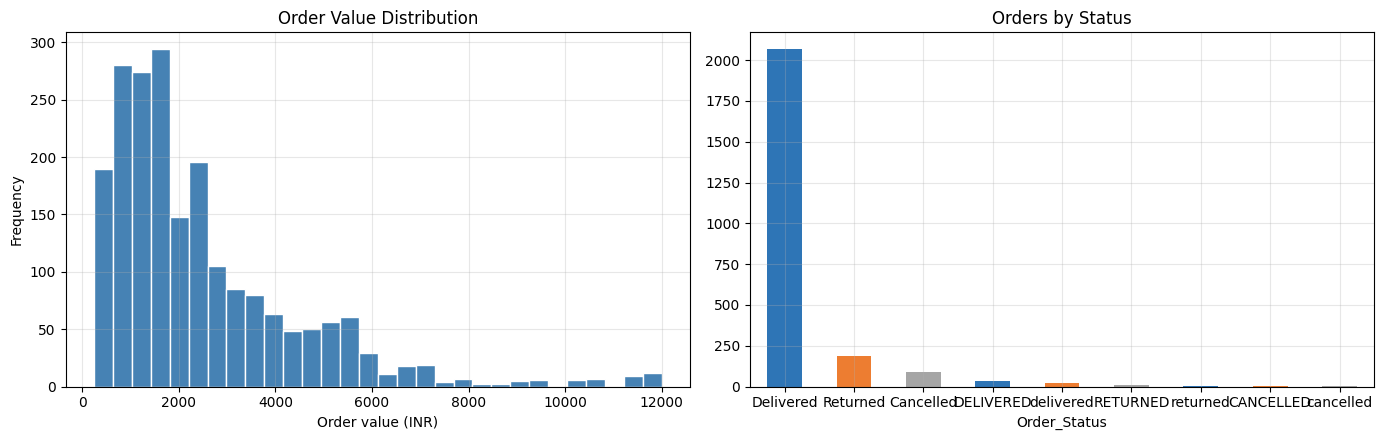

Median order value: 1799 | Mean: 2495


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sales['Revenue'].plot(kind='hist', bins=30, ax=ax[0], color='steelblue', edgecolor='white')
ax[0].set_title('Order Value Distribution'); ax[0].set_xlabel('Order value (INR)')
df['Order_Status'].value_counts().plot(kind='bar', ax=ax[1], color=['#2E75B6', '#ED7D31', '#A5A5A5'])
ax[1].set_title('Orders by Status'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig('charts/eda_overview.png', dpi=150, bbox_inches='tight'); plt.show()
print('Median order value:', round(sales['Revenue'].median()), '| Mean:', round(sales['Revenue'].mean()))

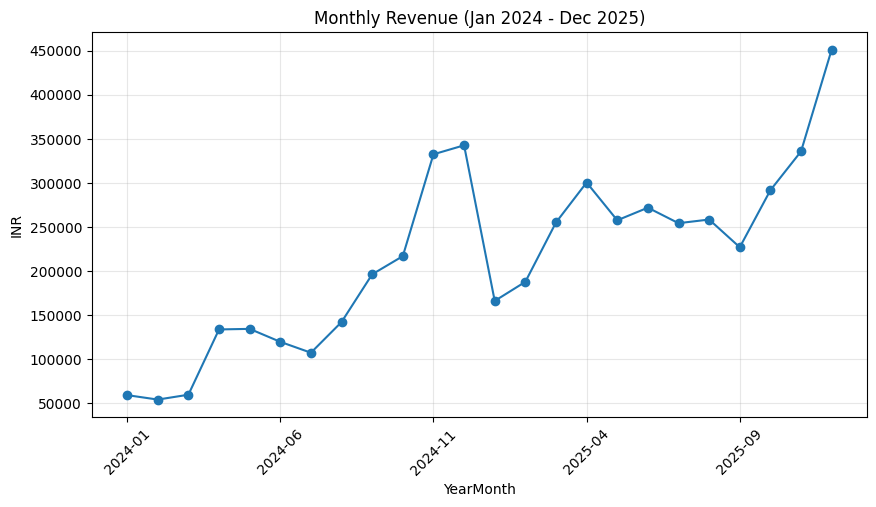

,Revenue,Orders,Customers,AOV,MoM_Growth_%
YearMonth,,,,,
2025-07,"254,286.95",97,88,"2,621.51",-6.47
2025-08,"258,432.95",105,98,"2,461.27",1.63
2025-09,"226,979.85",100,94,"2,269.80",-12.17
2025-10,"291,713.85",131,121,"2,226.82",28.52
2025-11,"335,725.90",148,133,"2,268.42",15.09
2025-12,"451,210.40",165,149,"2,734.61",34.40


In [21]:
monthly = sales.groupby('YearMonth').agg(Revenue=('Revenue', 'sum'), Orders=('Order_ID', 'count'),
                                          Customers=('Customer_ID', 'nunique'))
monthly['AOV'] = monthly['Revenue'] / monthly['Orders']
monthly['MoM_Growth_%'] = monthly['Revenue'].pct_change() * 100

monthly['Revenue'].plot(marker='o')
plt.title('Monthly Revenue (Jan 2024 - Dec 2025)'); plt.ylabel('INR'); plt.xticks(rotation=45)
plt.savefig('charts/monthly_revenue.png', dpi=150, bbox_inches='tight'); plt.show()
monthly.tail(6)

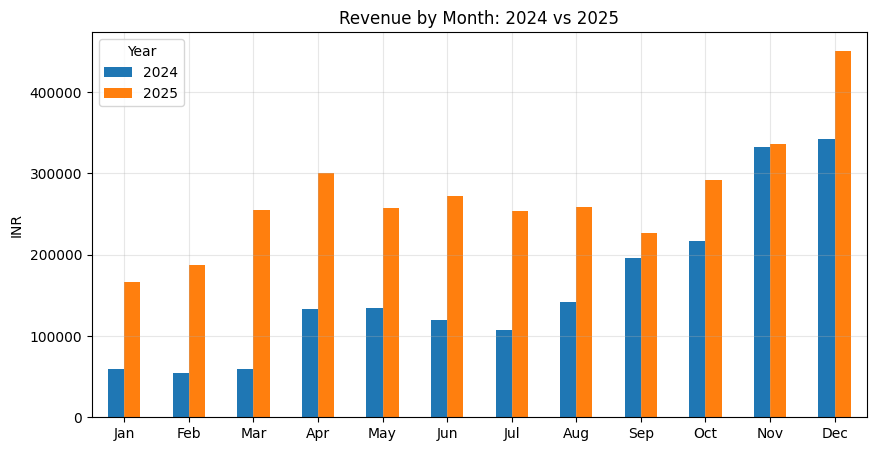

2024: INR 1,898,916 | 2025: INR 3,257,231 | Growth: 71.5%


Year,2024,2025,Growth_%
Jan,"59,261.35","166,115.05",180.31
Feb,"54,216.25","187,783.70",246.36
Mar,"59,719.60","255,092.50",327.15
Apr,"133,771.85","300,434.90",124.59
May,"134,412.55","257,576.50",91.63
Jun,"119,709.35","271,878.90",127.12
Jul,"107,356.70","254,286.95",136.86
Aug,"142,203.85","258,432.95",81.73
Sep,"196,315.05","226,979.85",15.62
Oct,"216,909.35","291,713.85",34.49


In [22]:
# Year-over-year comparison by month
yoy = sales.pivot_table(index='Month_Num', columns='Year', values='Revenue', aggfunc='sum')
yoy['Growth_%'] = (yoy[2025] / yoy[2024] - 1) * 100
yoy.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
yoy[[2024, 2025]].plot(kind='bar')
plt.title('Revenue by Month: 2024 vs 2025'); plt.ylabel('INR'); plt.xticks(rotation=0)
plt.savefig('charts/yoy.png', dpi=150, bbox_inches='tight'); plt.show()

yr = sales.groupby('Year')['Revenue'].sum()
print(f"2024: INR {yr[2024]:,.0f} | 2025: INR {yr[2025]:,.0f} | Growth: {(yr[2025]/yr[2024]-1)*100:.1f}%")
yoy

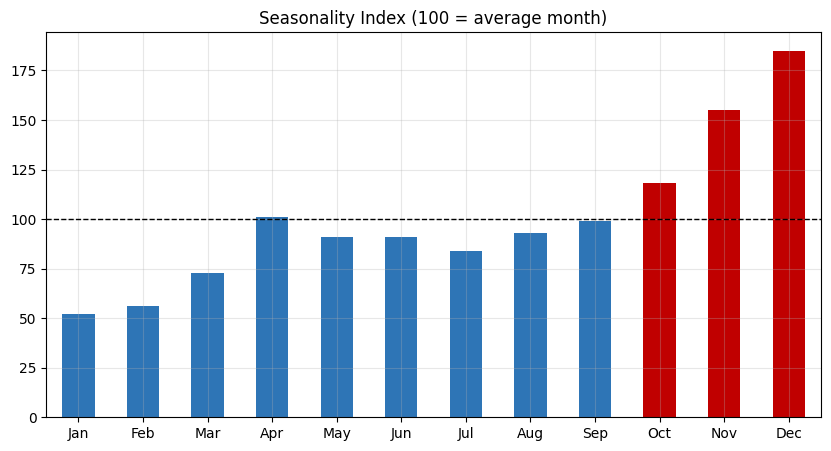

Q4 (Oct-Dec) share of total revenue: 38.2%


In [23]:
# Seasonality index: average month revenue vs overall average (100 = average)
seas = sales.groupby('Month_Num')['Revenue'].sum()
seas_idx = (seas / seas.mean() * 100).round(0)
seas_idx.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
colors = ['#C00000' if v >= 115 else '#2E75B6' for v in seas_idx]
seas_idx.plot(kind='bar', color=colors)
plt.axhline(100, color='black', linestyle='--', linewidth=1)
plt.title('Seasonality Index (100 = average month)'); plt.xticks(rotation=0)
plt.savefig('charts/seasonality.png', dpi=150, bbox_inches='tight'); plt.show()
q4_share = sales[sales['Quarter'] == 4]['Revenue'].sum() / revenue * 100
print(f'Q4 (Oct-Dec) share of total revenue: {q4_share:.1f}%')

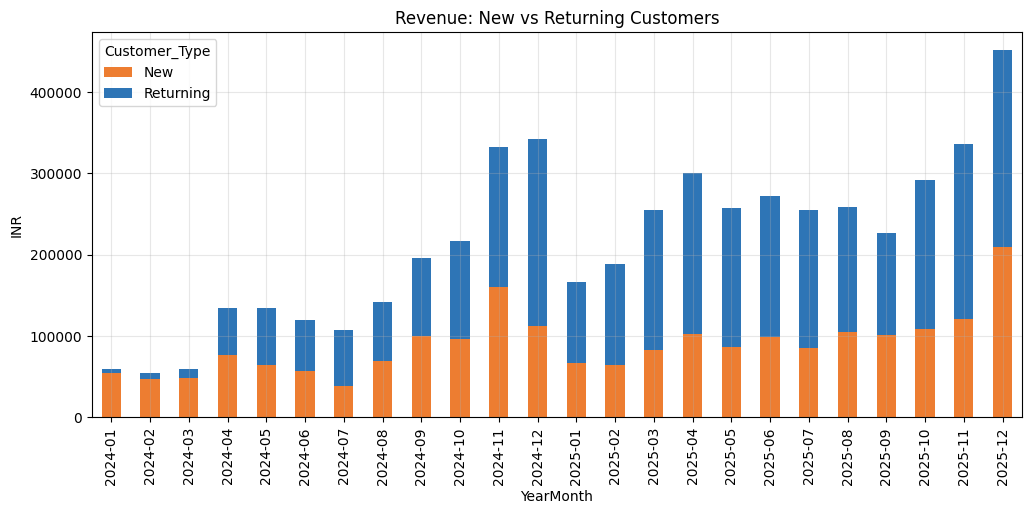

Customer_Type
New         41.70
Returning   58.30
Name: Revenue, dtype: float64


In [24]:
sales = sales.sort_values(['Customer_ID', 'Order_Date', 'Order_ID'])
sales['Order_Number'] = sales.groupby('Customer_ID').cumcount() + 1
sales['Customer_Type'] = np.where(sales['Order_Number'] == 1, 'New', 'Returning')

nr = sales.pivot_table(index='YearMonth', columns='Customer_Type', values='Revenue', aggfunc='sum').fillna(0)
nr.plot(kind='bar', stacked=True, color=['#ED7D31', '#2E75B6'], figsize=(12, 5))
plt.title('Revenue: New vs Returning Customers'); plt.ylabel('INR')
plt.savefig('charts/new_vs_returning.png', dpi=150, bbox_inches='tight'); plt.show()

ret_share = sales.groupby('Customer_Type')['Revenue'].sum() / revenue * 100
print(ret_share.round(1))

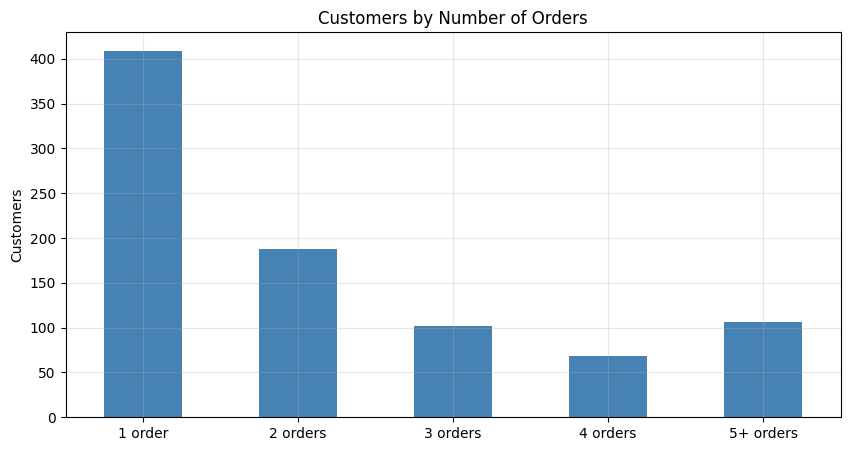

One-time buyers: 46.8% | Repeat customers: 53.2%
Median days between orders: 48


In [25]:
dist = cust_orders.clip(upper=5).value_counts().sort_index()
dist.index = ['1 order', '2 orders', '3 orders', '4 orders', '5+ orders']
dist.plot(kind='bar', color='steelblue')
plt.title('Customers by Number of Orders'); plt.xticks(rotation=0); plt.ylabel('Customers')
plt.savefig('charts/orders_per_customer.png', dpi=150, bbox_inches='tight'); plt.show()
print(f'One-time buyers: {(cust_orders == 1).mean() * 100:.1f}% | Repeat customers: {repeat_rate:.1f}%')

# Time between orders for repeat customers
gaps = sales.groupby('Customer_ID')['Order_Date'].diff().dt.days.dropna()
print(f'Median days between orders: {gaps.median():.0f}')

In [27]:
%%html
<h1> Cohort Retention (Quartly)</h1>

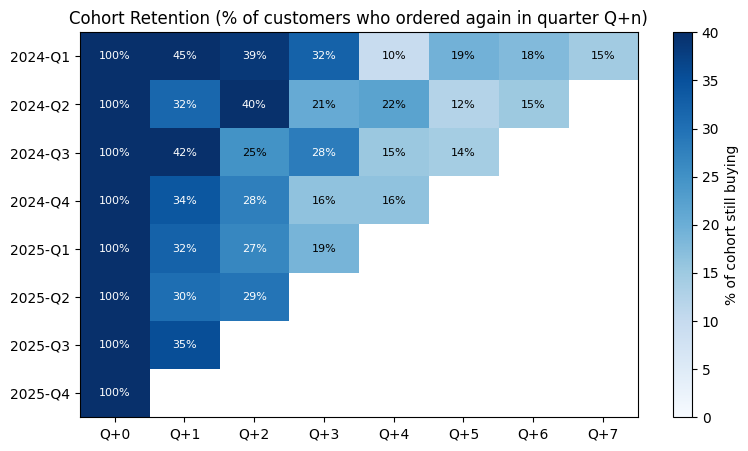

,Q+0,Q+1,Q+2,Q+3,Q+4,Q+5,Q+6,Q+7
2024-Q1,100.00,45.20,38.70,32.30,9.70,19.40,17.70,14.50
2024-Q2,100.00,31.50,39.70,20.50,21.90,12.30,15.10,NaN
2024-Q3,100.00,42.40,24.70,28.20,15.30,14.10,NaN,NaN
2024-Q4,100.00,34.00,27.70,16.40,16.40,NaN,NaN,NaN
2025-Q1,100.00,32.20,26.70,18.90,NaN,NaN,NaN,NaN
2025-Q2,100.00,30.40,29.50,NaN,NaN,NaN,NaN,NaN
2025-Q3,100.00,35.30,NaN,NaN,NaN,NaN,NaN,NaN
2025-Q4,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
sales['Q_Index'] = sales['Year'] * 4 + sales['Quarter']
first_q = sales.groupby('Customer_ID')['Q_Index'].min().rename('Cohort_Q')
sales = sales.join(first_q, on='Customer_ID')
sales['Quarters_Since'] = sales['Q_Index'] - sales['Cohort_Q']

cohort = sales.groupby(['Cohort_Q', 'Quarters_Since'])['Customer_ID'].nunique().unstack()
retention = cohort.div(cohort[0], axis=0) * 100
retention.index = [f"{(i - 1) // 4}-Q{(i - 1) % 4 + 1}" for i in retention.index]
retention.columns = [f'Q+{c}' for c in retention.columns]

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(retention.values, cmap='Blues', vmin=0, vmax=40, aspect='auto')
ax.set_xticks(range(len(retention.columns))); ax.set_xticklabels(retention.columns)
ax.set_yticks(range(len(retention.index))); ax.set_yticklabels(retention.index)
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}%', ha='center', va='center', fontsize=8, color='black' if v < 25 else 'white')
ax.grid(False); plt.colorbar(im, label='% of cohort still buying')
ax.set_title('Cohort Retention (% of customers who ordered again in quarter Q+n)')
plt.savefig('charts/cohort.png', dpi=150, bbox_inches='tight'); plt.show()
retention.round(1)

In [29]:
%%html
<h2>RFM Segmentation</h2>

In [28]:
ref_date = sales['Order_Date'].max() + pd.Timedelta(days=1)
rfm = sales.groupby('Customer_ID').agg(Recency=('Order_Date', lambda x: (ref_date - x.max()).days),
                                       Frequency=('Order_ID', 'count'),
                                       Monetary=('Revenue', 'sum'))
rfm['R'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1]).astype(int)       # recent = high score
rfm['F'] = rfm['Frequency'].clip(upper=4)                                      # 1,2,3,4+
rfm['M'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4]).astype(int)

rfm['Segment'] = np.select(
    [(rfm['F'] >= 3) & (rfm['R'] >= 3),
     (rfm['F'] >= 3),
     (rfm['F'] == 2) & (rfm['R'] >= 3),
     (rfm['F'] == 1) & (rfm['R'] == 4),
     (rfm['R'] <= 2)],
    ['Champions', 'At Risk (Loyal)', 'Potential Loyalists', 'New Customers', 'Lost / Hibernating'],
    default='Need Attention')

seg = rfm.groupby('Segment').agg(Customers=('Monetary', 'count'), Revenue=('Monetary', 'sum'),
                                 Avg_Orders=('Frequency', 'mean'), Avg_Recency_Days=('Recency', 'mean'))
seg['Customer_Share_%'] = seg['Customers'] / seg['Customers'].sum() * 100
seg['Revenue_Share_%'] = seg['Revenue'] / seg['Revenue'].sum() * 100
seg = seg.sort_values('Revenue', ascending=False)
seg

,Customers,Revenue,Avg_Orders,Avg_Recency_Days,Customer_Share_%,Revenue_Share_%
Segment,,,,,,
Champions,154,"1,923,308.60",5.01,62.69,17.64,37.30
At Risk (Loyal),122,"1,284,720.75",4.19,328.46,13.97,24.92
Lost / Hibernating,312,"999,537.10",1.29,377.79,35.74,19.39
Potential Loyalists,96,"496,170.85",2.00,54.61,11.00,9.62
New Customers,93,"236,896.15",1.00,24.20,10.65,4.59
Need Attention,96,"215,513.50",1.00,104.29,11.00,4.18


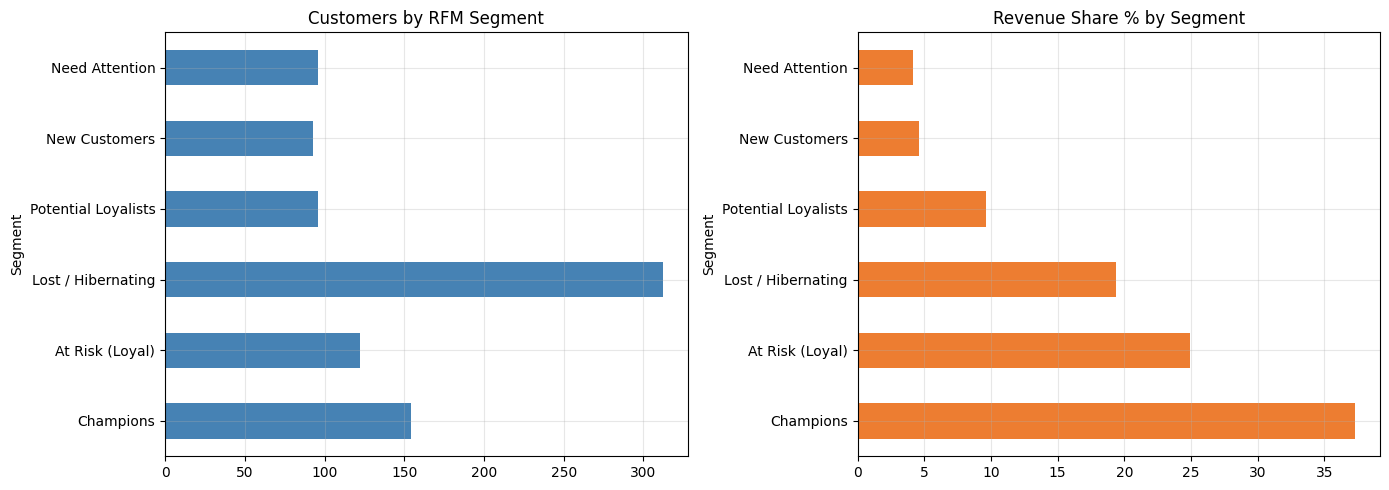

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
seg['Customers'].plot(kind='barh', ax=ax[0], color='steelblue'); ax[0].set_title('Customers by RFM Segment')
seg['Revenue_Share_%'].plot(kind='barh', ax=ax[1], color='#ED7D31'); ax[1].set_title('Revenue Share % by Segment')
plt.tight_layout(); plt.savefig('charts/rfm.png', dpi=150, bbox_inches='tight'); plt.show()

Top 5 products share of revenue: 40.7 %


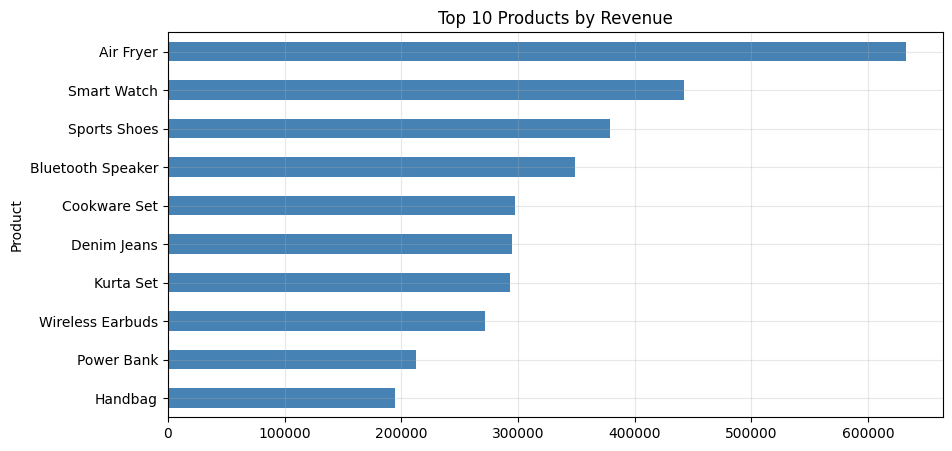

In [31]:
# Product concentration
prod = sales.groupby('Product')['Revenue'].sum().sort_values(ascending=False)
print('Top 5 products share of revenue:', round(prod.head(5).sum() / prod.sum() * 100, 1), '%')
prod.head(10).sort_values().plot(kind='barh', color='steelblue'); plt.title('Top 10 Products by Revenue')
plt.savefig('charts/top_products.png', dpi=150, bbox_inches='tight'); plt.show()

In [32]:
%%html
<h2>Segment Performance: Acquisition Channel ,Age , Gender

In [33]:
def segment_table(col):
    t = sales.groupby(col).agg(Customers=('Customer_ID', 'nunique'), Orders=('Order_ID', 'count'),
                               Revenue=('Revenue', 'sum'), Profit=('Profit', 'sum'))
    t['Revenue_per_Customer'] = t['Revenue'] / t['Customers']
    t['AOV'] = t['Revenue'] / t['Orders']
    t['Margin_%'] = t['Profit'] / t['Revenue'] * 100
    rep = sales.groupby([col, 'Customer_ID'])['Order_ID'].count().groupby(col).apply(lambda s: (s > 1).mean() * 100)
    t['Repeat_Rate_%'] = rep
    return t.sort_values('Revenue_per_Customer', ascending=False)

ch = segment_table('Acquisition_Channel')
ch

,Customers,Orders,Revenue,Profit,Revenue_per_Customer,AOV,Margin_%,Repeat_Rate_%
Acquisition_Channel,,,,,,,,
Referral,104,384,"871,186.55","392,718.55","8,376.79","2,268.71",45.08,69.23
Email Campaign,125,347,"906,708.05","395,609.05","7,253.66","2,612.99",43.63,63.20
Organic Search,240,576,"1,436,609.30","623,471.30","5,985.87","2,494.11",43.40,55.00
Email Campaign,1,1,"4,758.30","1,958.30","4,758.30","4,758.30",41.16,0.00
Social Media,194,370,"899,487.10","376,518.10","4,636.53","2,431.05",41.86,47.42
Paid Ads,200,336,"885,447.85","382,355.85","4,427.24","2,635.26",43.18,41.00
email campaign,4,5,"16,874.95","7,255.95","4,218.74","3,374.99",43.00,25.00
Social Media,5,5,"18,116.70","7,266.70","3,623.34","3,623.34",40.11,0.00
paid ads,6,7,"21,398.40","8,798.40","3,566.40","3,056.91",41.12,16.67


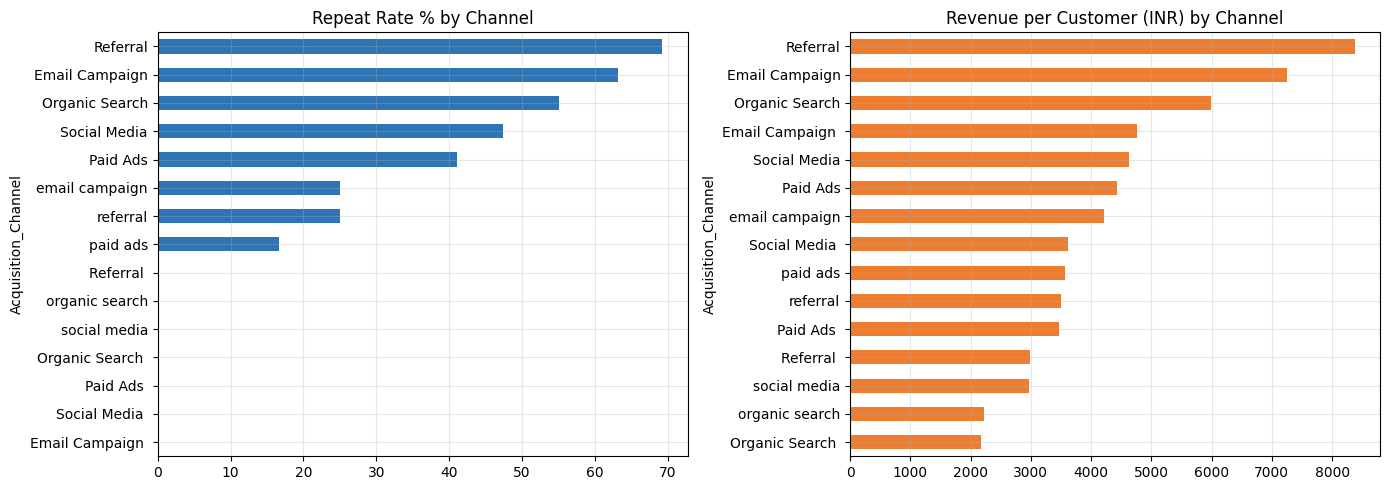

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ch['Repeat_Rate_%'].sort_values().plot(kind='barh', ax=ax[0], color='#2E75B6'); ax[0].set_title('Repeat Rate % by Channel')
ch['Revenue_per_Customer'].sort_values().plot(kind='barh', ax=ax[1], color='#ED7D31'); ax[1].set_title('Revenue per Customer (INR) by Channel')
plt.tight_layout(); plt.savefig('charts/channel.png', dpi=150, bbox_inches='tight'); plt.show()

In [35]:
display(segment_table('Age_Group'))
display(segment_table('Gender'))

,Customers,Orders,Revenue,Profit,Revenue_per_Customer,AOV,Margin_%,Repeat_Rate_%
Age_Group,,,,,,,,
55+,47,109,"290,098.20","123,066.20","6,172.30","2,661.45",42.42,53.19
25-34,324,794,"1,978,287.65","855,733.65","6,105.83","2,491.55",43.26,52.78
45-54,113,278,"681,256.55","294,813.55","6,028.82","2,450.56",43.27,54.87
35-44,207,488,"1,232,084.55","541,540.55","5,952.10","2,524.76",43.95,55.07
18-24,170,385,"947,869.85","409,194.85","5,575.70","2,462.00",43.17,53.53
Unknown,12,13,"26,550.15","11,962.15","2,212.51","2,042.32",45.05,8.33


,Customers,Orders,Revenue,Profit,Revenue_per_Customer,AOV,Margin_%,Repeat_Rate_%
Gender,,,,,,,,
Male,379,916,"2,299,995.20","999,791.20","6,068.59","2,510.91",43.47,54.62
Female,494,1151,"2,856,151.75","1,236,519.75","5,781.68","2,481.45",43.29,52.02


In [38]:
%%html
<h2> Churn like Pattern (inactive customers)

Typical gap between repeat orders (median): 48 days -> threshold chosen: 120 days
Overall inactive customers: 57.3%


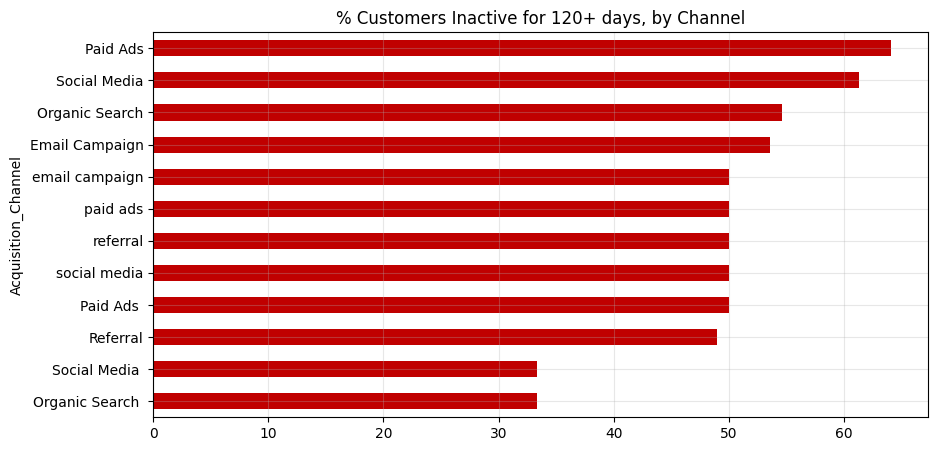

In [37]:
threshold = 120   # days. If a customer has not ordered for 120+ days we call them inactive/churned
print(f'Typical gap between repeat orders (median): {gaps.median():.0f} days -> threshold chosen: {threshold} days')

rfm_ch = rfm.join(sales.groupby('Customer_ID')['Acquisition_Channel'].first())
rfm_ch['Inactive'] = rfm_ch['Recency'] > threshold
churn = rfm_ch.groupby('Acquisition_Channel')['Inactive'].mean().sort_values() * 100
print(f"Overall inactive customers: {rfm_ch['Inactive'].mean() * 100:.1f}%")
churn.plot(kind='barh', color='#C00000'); plt.title(f'% Customers Inactive for {threshold}+ days, by Channel')
plt.savefig('charts/churn.png', dpi=150, bbox_inches='tight'); plt.show()

In [40]:
%%html
<h2>Category , Profit & Discount Analysis </h2>

In [39]:
rr = df[df['Order_Status'].isin(['Delivered', 'Returned'])].groupby('Category')['Order_Status'] \
        .apply(lambda s: (s == 'Returned').mean() * 100)
cat = sales.groupby('Category').agg(Revenue=('Revenue', 'sum'), Profit=('Profit', 'sum'), Orders=('Order_ID', 'count'))
cat['Margin_%'] = cat['Profit'] / cat['Revenue'] * 100
cat['Revenue_Share_%'] = cat['Revenue'] / cat['Revenue'].sum() * 100
cat['Return_Rate_%'] = rr
cat = cat.sort_values('Revenue', ascending=False)
cat

,Revenue,Profit,Orders,Margin_%,Revenue_Share_%,Return_Rate_%
Category,,,,,,
Electronics,"1,281,568.25","486,244.25",476,37.94,24.86,5.93
Fashion,"1,211,272.80","580,931.80",477,47.96,23.49,14.82
Home & Kitchen,"1,157,450.75","461,738.75",326,39.89,22.45,7.65
Beauty & Personal Care,"553,822.50","288,493.50",271,52.09,10.74,7.82
Sports & Fitness,"553,421.70","237,936.70",242,42.99,10.73,2.81
Books & Stationery,"171,343.25","79,817.25",180,46.58,3.32,4.76
FASHION,"35,592.25","16,994.25",11,47.75,0.69,15.38
ELECTRONICS,"34,047.90","12,880.90",15,37.83,0.66,6.25
Electronics,"31,886.80","13,306.80",10,41.73,0.62,0.00


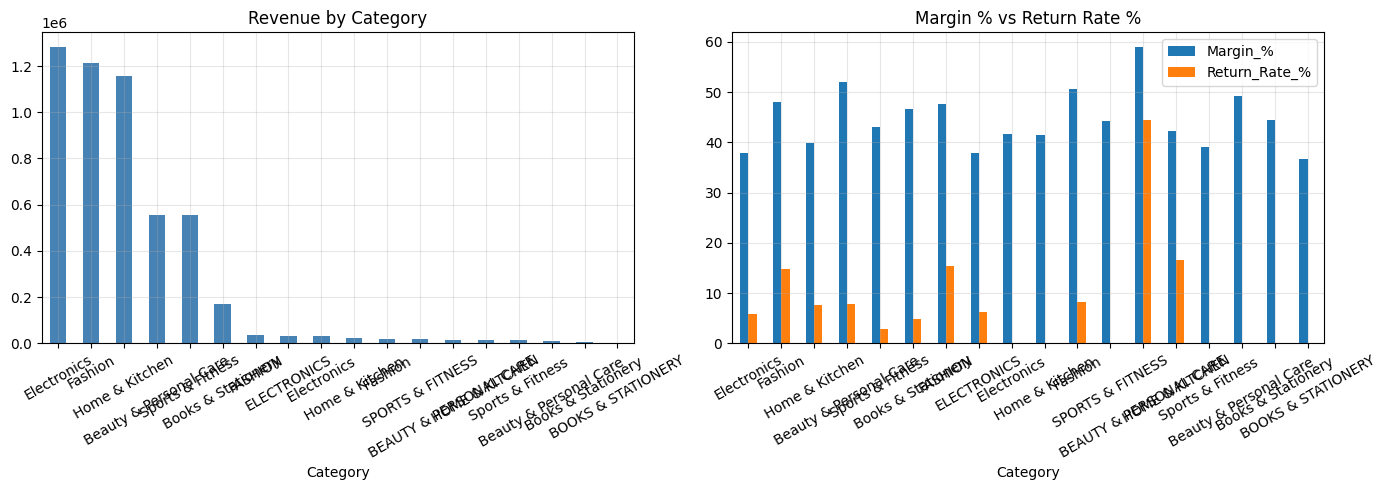

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cat['Revenue'].plot(kind='bar', ax=ax[0], color='steelblue'); ax[0].set_title('Revenue by Category'); ax[0].tick_params(axis='x', rotation=30)
cat[['Margin_%', 'Return_Rate_%']].plot(kind='bar', ax=ax[1]); ax[1].set_title('Margin % vs Return Rate %'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('charts/category.png', dpi=150, bbox_inches='tight'); plt.show()

,Orders,Revenue,Profit,Avg_Qty,AOV,Margin_%
Discount_Band,,,,,,
No discount,560,"1,548,066.00","749,775.00",1.58,"2,764.40",48.43
5-10%,824,"2,114,813.60","940,123.60",1.62,"2,566.52",44.45
15-20%,554,"1,255,585.85","482,793.85",1.62,"2,266.40",38.45
30%,129,"237,681.50","63,618.50",1.59,"1,842.49",26.77


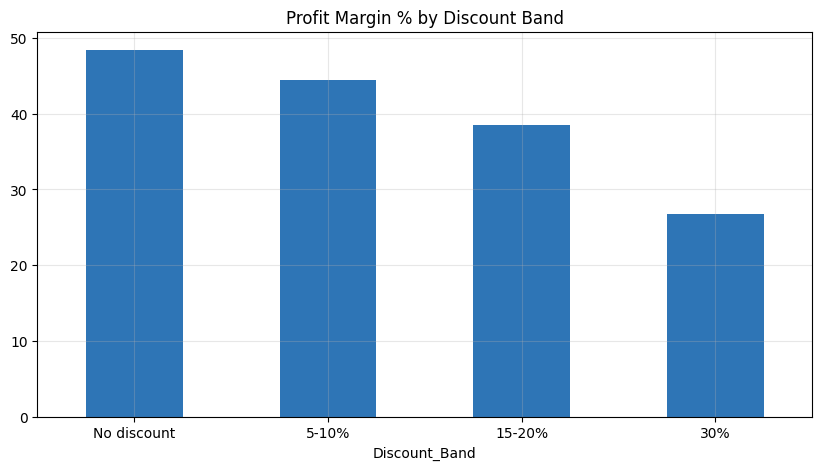

Average discount Oct-Dec: 12.9% vs rest of year: 7.1%


In [42]:
# Discount impact
bins = [-1, 0, 10, 20, 30]
labels = ['No discount', '5-10%', '15-20%', '30%']
sales['Discount_Band'] = pd.cut(sales['Discount_Pct'], bins=bins, labels=labels)
disc = sales.groupby('Discount_Band', observed=True).agg(Orders=('Order_ID', 'count'), Revenue=('Revenue', 'sum'),
                                                         Profit=('Profit', 'sum'), Avg_Qty=('Quantity', 'mean'))
disc['AOV'] = disc['Revenue'] / disc['Orders']
disc['Margin_%'] = disc['Profit'] / disc['Revenue'] * 100
display(disc)
disc['Margin_%'].plot(kind='bar', color='#2E75B6'); plt.title('Profit Margin % by Discount Band'); plt.xticks(rotation=0)
plt.savefig('charts/discount.png', dpi=150, bbox_inches='tight'); plt.show()

fest = sales[sales['Month_Num'].isin([10, 11, 12])]['Discount_Pct'].mean()
rest = sales[~sales['Month_Num'].isin([10, 11, 12])]['Discount_Pct'].mean()
print(f'Average discount Oct-Dec: {fest:.1f}% vs rest of year: {rest:.1f}%')

In [44]:
%%html
<h2> Regional Performance & Delivery Experience </h2>

In [43]:
valid = df[df['Order_Status'].isin(['Delivered', 'Returned'])]
reg = sales.groupby('Region').agg(Customers=('Customer_ID', 'nunique'), Revenue=('Revenue', 'sum'), Orders=('Order_ID', 'count'))
reg['AOV'] = reg['Revenue'] / reg['Orders']
reg['Revenue_per_Customer'] = reg['Revenue'] / reg['Customers']
reg['Avg_Delivery_Days'] = valid.groupby('Region')['Delivery_Days'].mean()
reg['Avg_Rating'] = df.groupby('Region')['Rating'].mean()
reg['Return_Rate_%'] = valid.groupby('Region')['Order_Status'].apply(lambda s: (s == 'Returned').mean() * 100)
reg = reg.sort_values('Revenue', ascending=False)
reg

,Customers,Revenue,Orders,AOV,Revenue_per_Customer,Avg_Delivery_Days,Avg_Rating,Return_Rate_%
Region,,,,,,,,
West,255,"1,642,870.00",638,"2,575.03","6,442.63",3.09,4.19,7.80
South,232,"1,418,517.25",574,"2,471.28","6,114.30",3.92,4.09,7.87
North,249,"1,311,402.35",532,"2,465.04","5,266.68",3.23,4.21,8.90
East,125,"585,542.50",244,"2,399.76","4,684.34",6.30,3.50,9.29
west,17,"47,351.10",18,"2,630.62","2,785.36",3.00,4.38,0.00
East,8,"29,452.00",8,"3,681.50","3,681.50",5.75,4.20,0.00
South,7,"29,299.00",7,"4,185.57","4,185.57",4.11,3.75,22.22
north,14,"26,670.95",15,"1,778.06","1,905.07",3.06,4.33,6.25
south,12,"23,473.80",12,"1,956.15","1,956.15",3.62,4.20,7.69


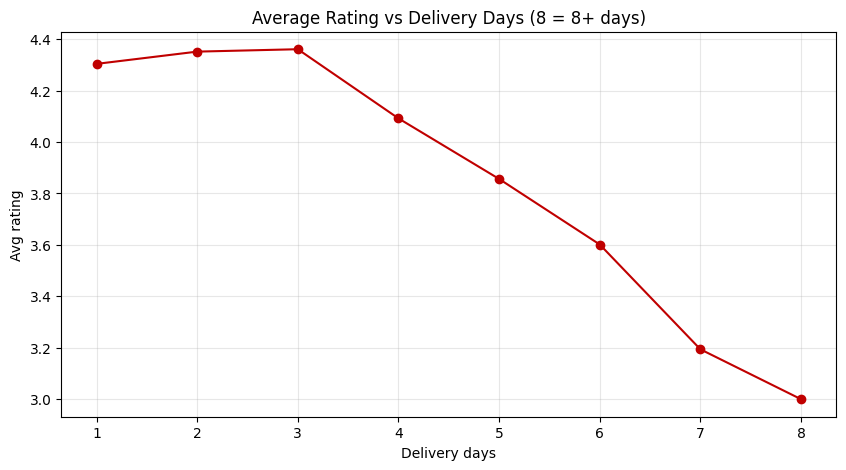

Correlation (delivery days vs rating): -0.38


In [45]:
dr = valid.copy()
dr['Delivery_Days'] = dr['Delivery_Days'].clip(upper=8)
dr_rating = dr.groupby('Delivery_Days')['Rating'].mean()
dr_rating.plot(marker='o', color='#C00000')
plt.title('Average Rating vs Delivery Days (8 = 8+ days)'); plt.xlabel('Delivery days'); plt.ylabel('Avg rating')
plt.savefig('charts/delivery_vs_rating.png', dpi=150, bbox_inches='tight'); plt.show()
print('Correlation (delivery days vs rating):', round(df[['Delivery_Days', 'Rating']].corr().iloc[0, 1], 2))

In [46]:
best_m = seas_idx.idxmax(); worst_m = seas_idx.idxmin()
best_ch = ch['Repeat_Rate_%'].idxmax(); worst_ch = ch['Repeat_Rate_%'].idxmin()
champ = seg.loc['Champions'] if 'Champions' in seg.index else None
fashion_rr = cat.loc['Fashion', 'Return_Rate_%']
slow_reg = reg['Avg_Delivery_Days'].idxmax()

print('KEY FINDINGS')
print('-' * 70)
print(f"1. Revenue INR {revenue:,.0f}, profit INR {profit:,.0f} (margin {margin:.1f}%), AOV INR {aov:,.0f}.")
print(f"2. Revenue grew {(yr[2025]/yr[2024]-1)*100:.1f}% from 2024 to 2025.")
print(f"3. Strongest month: {best_m} (index {seas_idx.max():.0f}); weakest: {worst_m} (index {seas_idx.min():.0f}). Q4 = {q4_share:.1f}% of revenue.")
print(f"4. Only {repeat_rate:.1f}% of customers buy more than once; returning customers give {ret_share['Returning']:.1f}% of revenue.")
print(f"5. Best channel for repeat buying: {best_ch} ({ch.loc[best_ch,'Repeat_Rate_%']:.1f}%); weakest: {worst_ch} ({ch.loc[worst_ch,'Repeat_Rate_%']:.1f}%).")
print(f"6. Top 20% of customers generate {top20:.1f}% of revenue.")
if champ is not None:
    print(f"7. Champions are {champ['Customer_Share_%']:.1f}% of customers but {champ['Revenue_Share_%']:.1f}% of revenue.")
print(f"8. Fashion return rate is {fashion_rr:.1f}% (highest category: {cat['Return_Rate_%'].idxmax()}).")
print(f"9. {slow_reg} has the slowest delivery ({reg.loc[slow_reg,'Avg_Delivery_Days']:.1f} days) and avg rating {reg.loc[slow_reg,'Avg_Rating']:.2f}.")
print(f"10. Highest-discount band margin: {disc['Margin_%'].iloc[-1]:.1f}% vs no-discount margin: {disc['Margin_%'].iloc[0]:.1f}%.")

KEY FINDINGS
----------------------------------------------------------------------
1. Revenue INR 5,156,147, profit INR 2,236,311 (margin 43.4%), AOV INR 2,495.
2. Revenue grew 71.5% from 2024 to 2025.
3. Strongest month: Dec (index 185); weakest: Jan (index 52). Q4 = 38.2% of revenue.
4. Only 53.2% of customers buy more than once; returning customers give 58.3% of revenue.
5. Best channel for repeat buying: Referral (69.2%); weakest: Email Campaign  (0.0%).


NameError: name 'top20' is not defined

In [47]:
df.to_csv('cleaned_ecommerce_orders.csv', index=False)
rfm.reset_index().to_csv('customer_rfm_segments.csv', index=False)

with pd.ExcelWriter('intermediate_analysis_summary.xlsx') as writer:
    kpi.to_excel(writer, sheet_name='KPIs', index=False)
    monthly.to_excel(writer, sheet_name='Monthly')
    seg.to_excel(writer, sheet_name='RFM_Segments')
    ch.to_excel(writer, sheet_name='Channel')
    cat.to_excel(writer, sheet_name='Category')
    disc.to_excel(writer, sheet_name='Discount')
    reg.to_excel(writer, sheet_name='Region')
    retention.to_excel(writer, sheet_name='Cohort_Retention')
print('Saved: cleaned_ecommerce_orders.csv, customer_rfm_segments.csv, intermediate_analysis_summary.xlsx, charts/*.png')

Saved: cleaned_ecommerce_orders.csv, customer_rfm_segments.csv, intermediate_analysis_summary.xlsx, charts/*.png
